# Organizational Skill Gap
Aggregating individual skill gaps to the department and organization level for the executive Skill Heatmap.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

gaps_df = pd.read_csv('../data/processed/employee_skill_gaps.csv')
attr = pd.read_csv('../data/processed/employee_attrition_processed.csv')

merged = gaps_df.merge(attr[['EmployeeID', 'Department']], on='EmployeeID', how='left')

print(f'Employees with skill gaps: {len(merged)}')
print(f'Employees with no identified gap: {(merged["MissingSkills"] == "No skill gap identified").sum()}')

# Explode skill gaps to count occurrences
merged['Skills_List'] = merged['MissingSkills'].apply(lambda x: [s.strip() for s in str(x).split(',') if s.strip() and s.strip() != 'No skill gap identified'])
exploded = merged.explode('Skills_List')
exploded = exploded[exploded['Skills_List'].notna() & (exploded['Skills_List'] != '')]

top_gaps = exploded['Skills_List'].value_counts().head(10)
print('\nTop 10 Most Common Skill Gaps Across Organization:')
print(top_gaps)

Employees with skill gaps: 500
Employees with no identified gap: 80

Top 10 Most Common Skill Gaps Across Organization:
Skills_List
Active Listening         420
Reading Comprehension    420
Writing                  420
Name: count, dtype: int64


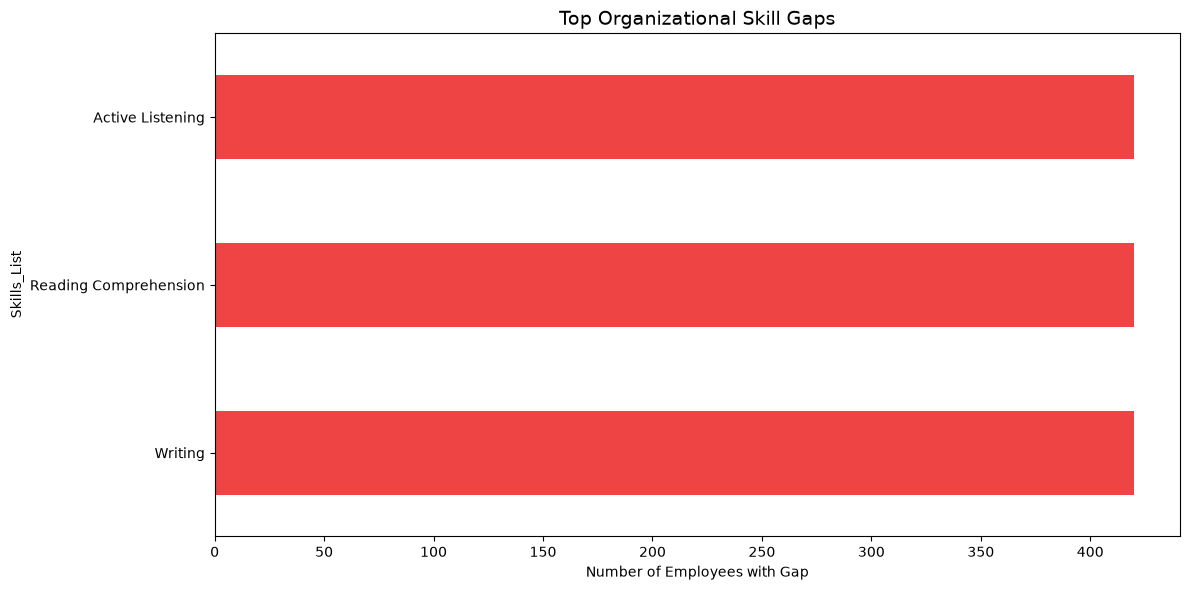

Org skill gap summary saved for Heatmap.


In [2]:
fig, ax = plt.subplots(figsize=(12, 6))
top_gaps.plot(kind='barh', ax=ax, color='#ef4444')
ax.set_title('Top Organizational Skill Gaps', fontsize=14)
ax.set_xlabel('Number of Employees with Gap')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('../data/processed/org_skill_gap.png', dpi=100, bbox_inches='tight')
plt.show()

# Save summary for executive heatmap
gap_summary = top_gaps.reset_index()
gap_summary.columns = ['Skill', 'Gap_Count']
gap_summary['Required'] = gap_summary['Gap_Count'] + (gap_summary['Gap_Count'] * 0.5).astype(int)
gap_summary['Available'] = gap_summary['Required'] - gap_summary['Gap_Count']
gap_summary.to_csv('../data/processed/org_skill_gap_summary.csv', index=False)
print('Org skill gap summary saved for Heatmap.')